APEXPLANET - TASK 4
ADVANCED ANALYTICS & STATISTICAL MODELING

Dataset: c:\Users\HP\OneDrive\Desktop\Task_1_EDA\notebooks\cleaned_dataset.csv
Reports folder: c:\Users\HP\OneDrive\Desktop\Task_1_EDA\reports

Original dataset shape: (21, 11)
Original columns: ['#', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']

Cleaned dataset shape: (20, 10)
Sales column: Total_Sales
Date column: Date
Category column: Category
Customer/group column: Customer_Type


,Date,Invoice_ID,City,Customer_Type,Gender,Category,Product,Unit_Price,Quantity,Total_Sales
1,2026-01-02,A001,Mandalay,Member,Female,Food,Bread,120.0,2.0,240.0
2,2026-01-03,A002,Yangon,Normal,Male,Beverages,Coffee,250.0,3.0,750.0
3,2026-01-05,A003,Naypyitaw,Member,Female,Food,Cake,180.0,2.0,360.0
4,2026-01-07,A004,Mandalay,Normal,Female,Personal Care,Shampoo,320.0,1.0,320.0
5,2026-01-09,A005,Yangon,Member,Male,Food,Rice,90.0,5.0,450.0



3. STATISTICAL ANALYSIS


,count,mean,std,min,25%,50%,75%,max,median,variance,skewness,kurtosis,mode
Unit_Price,20.0,222.00,196.082689,60.0,90.0,150.0,267.5,800.0,150.0,38448.421053,1.833263,3.224103,60.0
Quantity,20.0,3.55,2.064104,1.0,2.0,3.0,5.0,8.0,3.0,4.260526,0.639080,-0.471623,2.0
Total_Sales,20.0,523.50,187.876639,240.0,360.0,520.0,632.5,900.0,520.0,35297.631579,0.263670,-0.686624,240.0



Sales Statistics
Count: 20
Total Sales: 10470.0
Mean: 523.5
Median: 520.0
Mode: [240.0, 360.0, 600.0, 750.0]
Variance: 35297.63
Standard Deviation: 187.88
Minimum: 240.0
Maximum: 900.0
95% Confidence Interval: (np.float64(435.57102619741465), np.float64(611.4289738025853))

4. HYPOTHESIS TESTING
T-test statistic: 0.08331251774729219
T-test p-value: 0.9344745491663493
ANOVA statistic: 4.328891130000481
ANOVA p-value: 0.020503982661078564
Chi-square statistic: 0.8417508417508415
Chi-square p-value: 0.8394568954714563


,Test,Statistic,P_Value,Significant_at_0.05
0,Exploratory One-Sample T-Test,0.083313,0.934475,False
1,ANOVA Across Categories,4.328891,0.020504,True
2,Chi-Square Category vs Gender,0.841751,0.839457,False


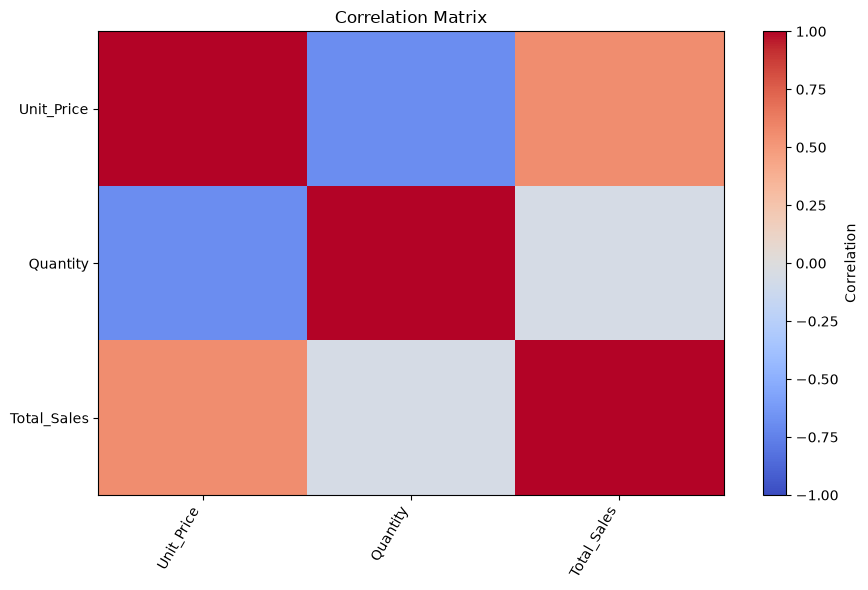

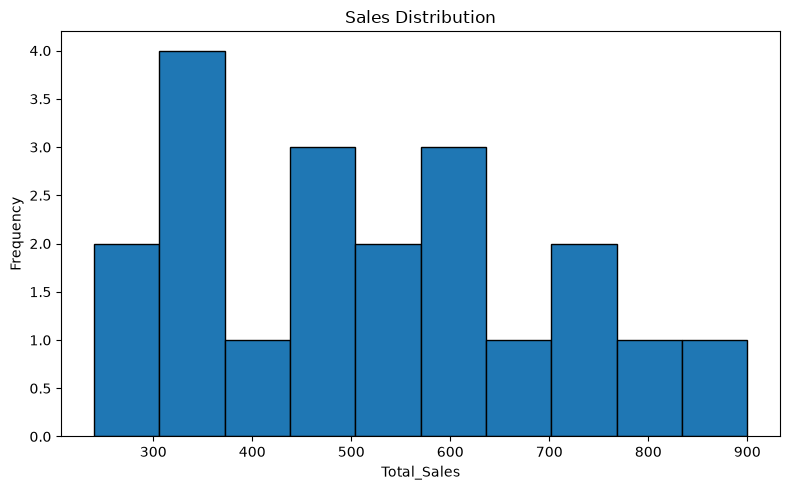

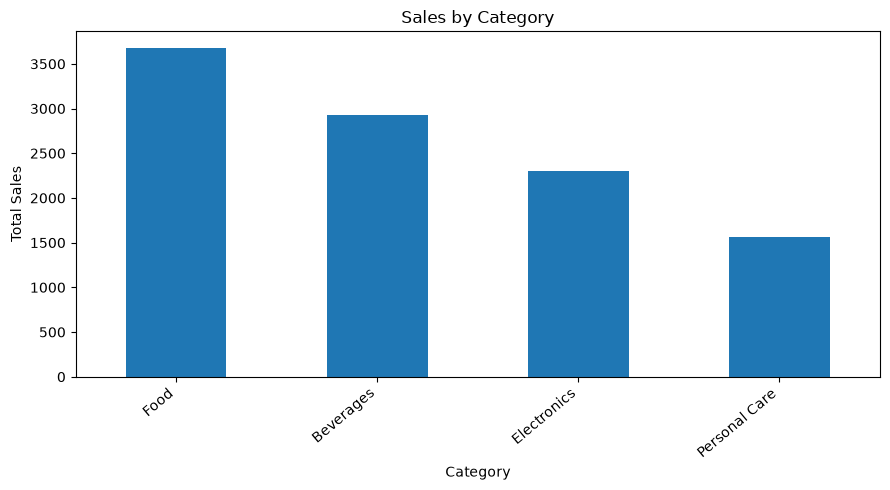

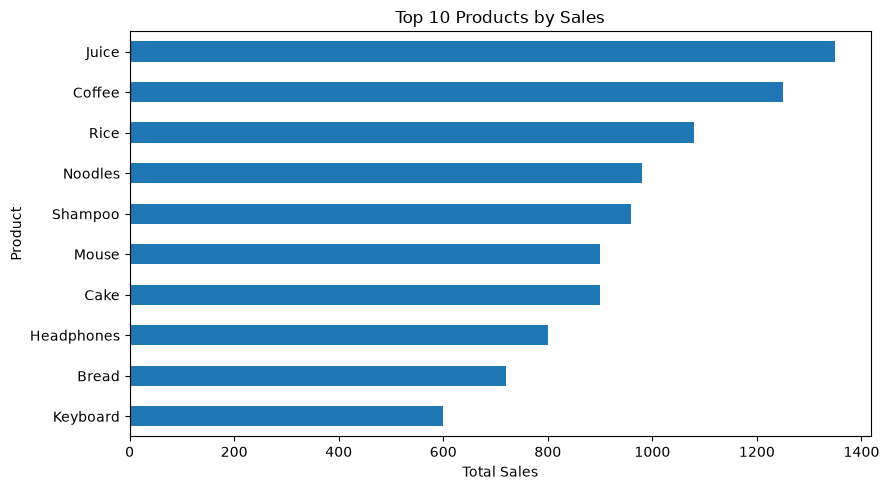


7. TIME SERIES ANALYSIS


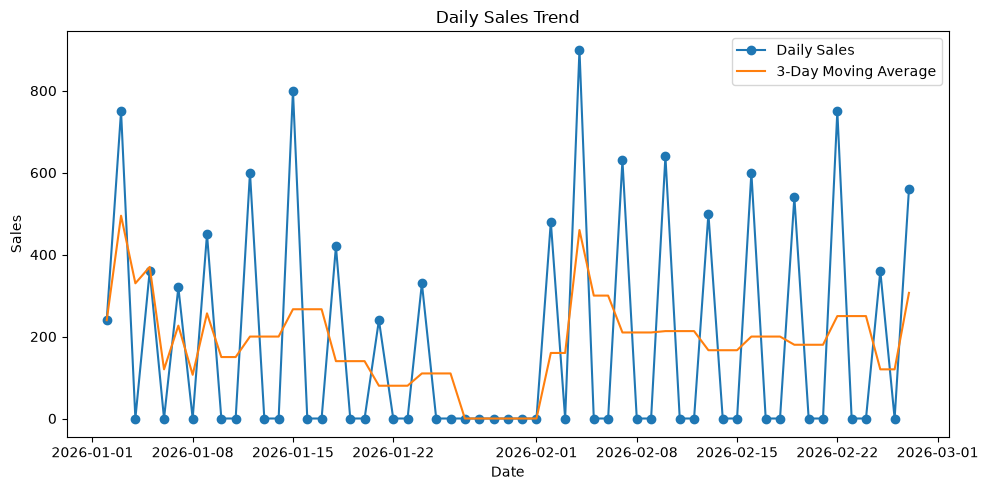

Forecast MAE: 262.54
Forecast RMSE: 295.57
Forecast MAPE: 67.95


,Date,Forecast_Sales
0,2026-02-28,238.571429
1,2026-03-01,238.571429
2,2026-03-02,238.571429
3,2026-03-03,238.571429
4,2026-03-04,238.571429
5,2026-03-05,238.571429
6,2026-03-06,238.571429


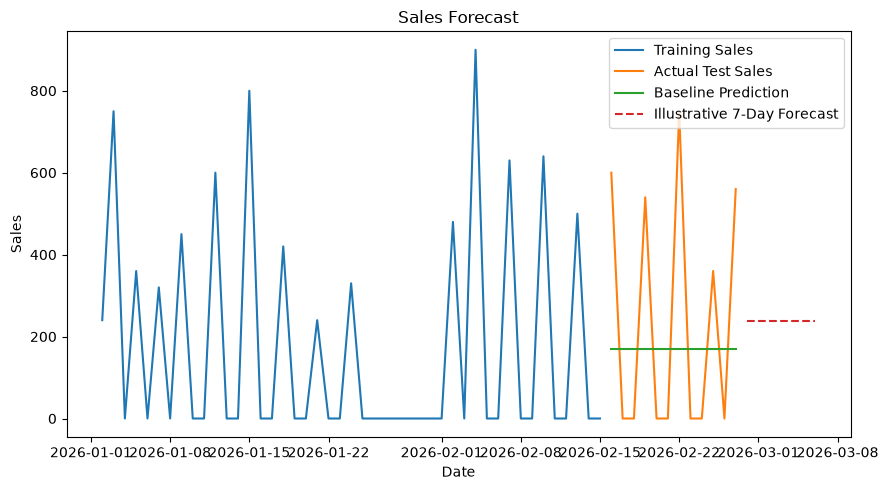


8. CUSTOMER SEGMENTATION
Clustering skipped: at least 3 customer/group records and a varying numeric feature are needed.

9. PREDICTIVE MODELING
Linear Regression MAE: 192.97
Linear Regression RMSE: 210.8
Linear Regression R2: 0.174


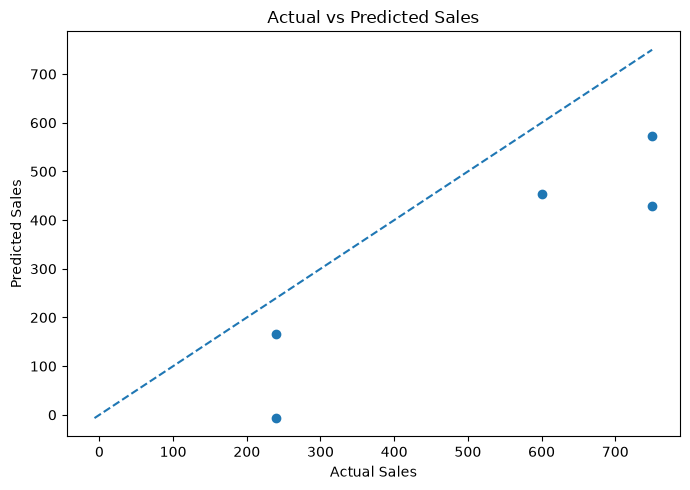


 Logistic Regression
              precision    recall  f1-score   support

           0       0.67      0.67      0.67         3
           1       0.50      0.50      0.50         2

    accuracy                           0.60         5
   macro avg       0.58      0.58      0.58         5
weighted avg       0.60      0.60      0.60         5

Confusion Matrix:
 [[2 1]
 [1 1]]

 Decision Tree
              precision    recall  f1-score   support

           0       0.33      0.33      0.33         3
           1       0.00      0.00      0.00         2

    accuracy                           0.20         5
   macro avg       0.17      0.17      0.17         5
weighted avg       0.20      0.20      0.20         5

Confusion Matrix:
 [[1 2]
 [2 0]]


,Model,MAE,RMSE,R2,Accuracy,Precision,Recall,F1
0,Linear Regression - Sales,192.967077,210.798894,0.173803,NaN,NaN,NaN,NaN
1,Logistic Regression - High/Low Sales,NaN,NaN,NaN,0.6,0.5,0.5,0.5
2,Decision Tree - High/Low Sales,NaN,NaN,NaN,0.2,0.0,0.0,0.0



TASK 4 NOTEBOOK EXECUTION FINISHED

Generated reports:
- category_sales.csv
- correlation_matrix.csv
- daily_sales_time_series.csv
- EDA_Report.md
- forecast_metrics.csv
- hypothesis_test_results.csv
- model_results.csv
- sales_forecast_7_days.csv
- statistical_summary.csv
- task3_summary.csv
- task3_visualizations
- task4_figures
- task4_final_summary.txt
- task4_sales_summary.csv
- top_products.csv

Graphs folder: c:\Users\HP\OneDrive\Desktop\Task_1_EDA\reports\task4_figures
Please review saved metrics and graphs before publishing.


In [4]:

# ================================================================
# APEXPLANET - TASK 4
# ADVANCED ANALYTICS & STATISTICAL MODELING
# Statistical Analysis | Time Series | Clustering | Machine Learning
# ================================================================

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    silhouette_score
)

print("=" * 65)
print("APEXPLANET - TASK 4")
print("ADVANCED ANALYTICS & STATISTICAL MODELING")
print("=" * 65)

# ================================================================
# 1. FIND PROJECT AND DATASET
# ================================================================

current = Path.cwd()
possible_roots = [current, current.parent, current.parent.parent]

data_path = None

for root in possible_roots:
    candidates = [
        root / "notebooks" / "cleaned_dataset.csv",
        root / "data" / "cleaned" / "sales.csv",
        root / "data" / "cleaned_dataset.csv",
        root / "cleaned_dataset.csv",
        root / "data" / "sales.csv"
    ]

    for path in candidates:
        if path.exists():
            data_path = path
            break

    if data_path:
        break

if data_path is None:
    for root in possible_roots:
        if root.exists():
            matches = (
                list(root.glob("**/cleaned_dataset.csv"))
                + list(root.glob("**/sales.csv"))
            )
            matches = [
                p for p in matches
                if ".git" not in p.parts
                and "site-packages" not in p.parts
            ]
            if matches:
                data_path = matches[0]
                break

if data_path is None:
    raise FileNotFoundError(
        "Dataset nahi mila. cleaned_dataset.csv ko notebooks folder "
        "mein ya sales.csv ko data/cleaned folder mein rakho."
    )

project_root = next(
    (
        root for root in possible_roots
        if (root / "notebooks").exists()
        or (root / "data").exists()
        or (root / ".git").exists()
    ),
    data_path.parent
)

reports = project_root / "reports"
figures = reports / "task4_figures"

reports.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)

print("\nDataset:", data_path)
print("Reports folder:", reports)

# ================================================================
# 2. LOAD AND CLEAN DATA
# ================================================================

df = pd.read_csv(data_path)

print("\nOriginal dataset shape:", df.shape)
print("Original columns:", list(df.columns))

# Handle the generic headers from the earlier Task 3 dataset.
# The file may have an extra first index column named '#'.
if len(df.columns) == 11:
    first_name = str(df.columns[0]).strip().lower()
    remaining = list(df.columns[1:])

    if first_name == "#" and all(
        str(c).strip().lower() in
        {"a", "b", "c", "d", "e", "f", "g", "h", "i", "j"}
        for c in remaining
    ):
        df = df.iloc[:, 1:].copy()

if len(df.columns) == 10 and all(
    str(c).strip().lower() in
    {"#", "a", "b", "c", "d", "e", "f", "g", "h", "i", "j"}
    for c in df.columns
):
    df.columns = [
        "Date",
        "Invoice_ID",
        "City",
        "Customer_Type",
        "Gender",
        "Category",
        "Product",
        "Unit_Price",
        "Quantity",
        "Total_Sales"
    ]

df.columns = [str(c).strip() for c in df.columns]

def normalize_name(name):
    return "".join(
        ch.lower() for ch in str(name)
        if ch.isalnum()
    )

def find_column(aliases):
    columns = {
        normalize_name(c): c
        for c in df.columns
    }

    for alias in aliases:
        if normalize_name(alias) in columns:
            return columns[normalize_name(alias)]

    for column in df.columns:
        for alias in aliases:
            if (
                len(normalize_name(alias)) >= 4
                and normalize_name(alias) in normalize_name(column)
            ):
                return column

    return None

date_col = find_column([
    "Date", "Order Date", "Invoice Date", "Transaction Date"
])

sales_col = find_column([
    "Total_Sales", "Total Sales", "Sales", "Revenue", "Amount"
])

quantity_col = find_column([
    "Quantity", "Qty", "Units Sold"
])

price_col = find_column([
    "Unit_Price", "Unit Price", "Price"
])

category_col = find_column([
    "Category", "Product Category"
])

product_col = find_column([
    "Product", "Product Name", "Item"
])

customer_col = find_column([
    "Customer_ID", "Customer ID", "Customer",
    "Customer_Type", "Customer Type"
])

region_col = find_column([
    "City", "Region", "State", "Location"
])

gender_col = find_column([
    "Gender", "Sex"
])

invoice_col = find_column([
    "Invoice_ID", "Invoice ID", "Order ID", "Transaction ID"
])

for col in [sales_col, quantity_col, price_col]:
    if col:
        df[col] = pd.to_numeric(
            df[col].astype(str)
            .str.replace(",", "", regex=False)
            .str.replace("$", "", regex=False),
            errors="coerce"
        )

if date_col:
    df[date_col] = pd.to_datetime(
        df[date_col],
        errors="coerce"
    )

if sales_col is None and price_col and quantity_col:
    sales_col = "Calculated_Sales"
    df[sales_col] = df[price_col] * df[quantity_col]

if sales_col is None:
    raise ValueError(
        "Sales column detect nahi hua. Upar printed column names check karo."
    )

df = df.dropna(how="all")
df = df.dropna(subset=[sales_col]).copy()

if df.empty:
    raise ValueError("Dataset mein usable sales values nahi mile.")

if customer_col is None:
    customer_col = invoice_col or region_col

if customer_col is None:
    customer_col = "_Customer_Group"
    df[customer_col] = [
        "Group_" + str(i) for i in range(len(df))
    ]

sales = df[sales_col].astype(float).dropna()

print("\nCleaned dataset shape:", df.shape)
print("Sales column:", sales_col)
print("Date column:", date_col)
print("Category column:", category_col)
print("Customer/group column:", customer_col)

display(df.head())

# ================================================================
# 3. STATISTICAL ANALYSIS
# ================================================================

print("\n" + "=" * 50)
print("3. STATISTICAL ANALYSIS")
print("=" * 50)

numeric_df = df.select_dtypes(include=np.number)

statistics_table = numeric_df.describe().T
statistics_table["median"] = numeric_df.median()
statistics_table["variance"] = numeric_df.var()
statistics_table["skewness"] = numeric_df.skew()
statistics_table["kurtosis"] = numeric_df.kurtosis()

if not numeric_df.mode().empty:
    statistics_table["mode"] = numeric_df.mode().iloc[0]

statistics_table.to_csv(
    reports / "statistical_summary.csv"
)

display(statistics_table)

print("\nSales Statistics")
print("Count:", len(sales))
print("Total Sales:", round(sales.sum(), 2))
print("Mean:", round(sales.mean(), 2))
print("Median:", round(sales.median(), 2))
print("Mode:", sales.mode().tolist())
print("Variance:", round(sales.var(), 2))
print("Standard Deviation:", round(sales.std(), 2))
print("Minimum:", round(sales.min(), 2))
print("Maximum:", round(sales.max(), 2))

if len(sales) > 1:
    confidence_interval = stats.t.interval(
        0.95,
        len(sales) - 1,
        loc=sales.mean(),
        scale=stats.sem(sales)
    )

    print(
        "95% Confidence Interval:",
        confidence_interval
    )

sales_summary = pd.DataFrame({
    "Metric": [
        "Number of Rows",
        "Total Sales",
        "Mean Sales",
        "Median Sales",
        "Standard Deviation",
        "Minimum Sales",
        "Maximum Sales"
    ],
    "Value": [
        len(sales),
        sales.sum(),
        sales.mean(),
        sales.median(),
        sales.std(),
        sales.min(),
        sales.max()
    ]
})

sales_summary.to_csv(
    reports / "task4_sales_summary.csv",
    index=False
)

# ================================================================
# 4. HYPOTHESIS TESTING
# ================================================================

print("\n" + "=" * 50)
print("4. HYPOTHESIS TESTING")
print("=" * 50)

test_results = []

# One-sample t-test: exploratory comparison with the sample median.
if len(sales) >= 2 and sales.std() > 0:
    t_stat, p_value = stats.ttest_1samp(
        sales,
        popmean=sales.median()
    )

    test_results.append({
        "Test": "Exploratory One-Sample T-Test",
        "Statistic": t_stat,
        "P_Value": p_value
    })

    print("T-test statistic:", t_stat)
    print("T-test p-value:", p_value)

# ANOVA: compare sales across categories.
if category_col:
    groups = [
        group[sales_col].dropna().values
        for _, group in df.groupby(category_col)
        if group[sales_col].notna().sum() >= 2
    ]

    if len(groups) >= 2:
        f_stat, p_value = stats.f_oneway(*groups)

        test_results.append({
            "Test": "ANOVA Across Categories",
            "Statistic": f_stat,
            "P_Value": p_value
        })

        print("ANOVA statistic:", f_stat)
        print("ANOVA p-value:", p_value)

# Chi-square: category and gender association.
if (
    category_col
    and gender_col
    and df[category_col].nunique() > 1
    and df[gender_col].nunique() > 1
):
    contingency_table = pd.crosstab(
        df[category_col],
        df[gender_col]
    )

    if (
        contingency_table.shape[0] >= 2
        and contingency_table.shape[1] >= 2
    ):
        chi2, p_value, dof, expected = (
            stats.chi2_contingency(contingency_table)
        )

        test_results.append({
            "Test": "Chi-Square Category vs Gender",
            "Statistic": chi2,
            "P_Value": p_value
        })

        print("Chi-square statistic:", chi2)
        print("Chi-square p-value:", p_value)

test_df = pd.DataFrame(test_results)

if not test_df.empty:
    test_df["Significant_at_0.05"] = (
        test_df["P_Value"] < 0.05
    )
    display(test_df)
else:
    print("No suitable hypothesis test for the available data.")

test_df.to_csv(
    reports / "hypothesis_test_results.csv",
    index=False
)

# ================================================================
# 5. CORRELATION ANALYSIS
# ================================================================

if len(numeric_df.columns) >= 2:
    correlation = numeric_df.corr()

    correlation.to_csv(
        reports / "correlation_matrix.csv"
    )

    plt.figure(figsize=(9, 6))
    plt.imshow(
        correlation,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        aspect="auto"
    )
    plt.colorbar(label="Correlation")

    plt.xticks(
        range(len(correlation.columns)),
        correlation.columns,
        rotation=60,
        ha="right"
    )

    plt.yticks(
        range(len(correlation.columns)),
        correlation.columns
    )

    plt.title("Correlation Matrix")
    plt.tight_layout()
    plt.savefig(
        figures / "correlation_matrix.png",
        dpi=150
    )
    plt.show()

# ================================================================
# 6. SALES VISUALIZATION
# ================================================================

plt.figure(figsize=(8, 5))
plt.hist(
    sales,
    bins=min(10, max(3, len(sales))),
    edgecolor="black"
)
plt.title("Sales Distribution")
plt.xlabel(sales_col)
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(
    figures / "sales_distribution.png",
    dpi=150
)
plt.show()

if category_col:
    category_sales = (
        df.groupby(category_col)[sales_col]
        .sum()
        .sort_values(ascending=False)
    )

    category_sales.to_csv(
        reports / "category_sales.csv"
    )

    plt.figure(figsize=(9, 5))
    category_sales.plot(kind="bar")
    plt.title("Sales by Category")
    plt.xlabel("Category")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.savefig(
        figures / "sales_by_category.png",
        dpi=150
    )
    plt.show()

if product_col:
    top_products = (
        df.groupby(product_col)[sales_col]
        .sum()
        .nlargest(10)
    )

    top_products.to_csv(
        reports / "top_products.csv"
    )

    plt.figure(figsize=(9, 5))
    top_products.sort_values().plot(kind="barh")
    plt.title("Top 10 Products by Sales")
    plt.xlabel("Total Sales")
    plt.tight_layout()
    plt.savefig(
        figures / "top_products.png",
        dpi=150
    )
    plt.show()

# ================================================================
# 7. TIME SERIES ANALYSIS AND FORECAST
# ================================================================

print("\n" + "=" * 50)
print("7. TIME SERIES ANALYSIS")
print("=" * 50)

forecast_results = []

if date_col and df[date_col].notna().sum() >= 3:

    time_series = (
        df.dropna(subset=[date_col])
        .set_index(date_col)[sales_col]
        .resample("D")
        .sum()
        .asfreq("D", fill_value=0)
        .sort_index()
    )

    time_series.rename("Sales").to_csv(
        reports / "daily_sales_time_series.csv"
    )

    plt.figure(figsize=(10, 5))
    plt.plot(
        time_series.index,
        time_series.values,
        marker="o",
        label="Daily Sales"
    )

    plt.plot(
        time_series.index,
        time_series.rolling(3, min_periods=1).mean(),
        label="3-Day Moving Average"
    )

    plt.title("Daily Sales Trend")
    plt.xlabel("Date")
    plt.ylabel("Sales")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        figures / "daily_sales_trend.png",
        dpi=150
    )
    plt.show()

    if len(time_series) >= 5:
        split_point = max(
            2,
            int(len(time_series) * 0.8)
        )

        train = time_series.iloc[:split_point]
        test = time_series.iloc[split_point:]

        if len(test) > 0:
            predictions = np.repeat(
                train.mean(),
                len(test)
            )

            mae = mean_absolute_error(
                test,
                predictions
            )

            rmse = np.sqrt(
                mean_squared_error(
                    test,
                    predictions
                )
            )

            nonzero = test.to_numpy() != 0

            if nonzero.any():
                mape = np.mean(
                    np.abs(
                        (
                            test.to_numpy()[nonzero]
                            - predictions[nonzero]
                        )
                        / test.to_numpy()[nonzero]
                    )
                ) * 100
            else:
                mape = np.nan

            forecast_results.append({
                "Model": "Mean Baseline",
                "MAE": mae,
                "RMSE": rmse,
                "MAPE_Percent": mape
            })

            print("Forecast MAE:", round(mae, 2))
            print("Forecast RMSE:", round(rmse, 2))
            print("Forecast MAPE:", round(mape, 2))

            future_dates = pd.date_range(
                start=time_series.index.max()
                + pd.Timedelta(days=1),
                periods=7,
                freq="D"
            )

            future_sales = np.repeat(
                time_series.tail(
                    min(7, len(time_series))
                ).mean(),
                7
            )

            forecast_df = pd.DataFrame({
                "Date": future_dates,
                "Forecast_Sales": future_sales
            })

            forecast_df.to_csv(
                reports / "sales_forecast_7_days.csv",
                index=False
            )

            display(forecast_df)

            plt.figure(figsize=(9, 5))
            plt.plot(
                train.index,
                train.values,
                label="Training Sales"
            )
            plt.plot(
                test.index,
                test.values,
                label="Actual Test Sales"
            )
            plt.plot(
                test.index,
                predictions,
                label="Baseline Prediction"
            )
            plt.plot(
                future_dates,
                future_sales,
                "--",
                label="Illustrative 7-Day Forecast"
            )
            plt.title("Sales Forecast")
            plt.xlabel("Date")
            plt.ylabel("Sales")
            plt.legend()
            plt.tight_layout()
            plt.savefig(
                figures / "sales_forecast.png",
                dpi=150
            )
            plt.show()

    else:
        print(
            "Forecast evaluation skipped: "
            "not enough daily observations."
        )

else:
    print(
        "Time-series analysis skipped: "
        "a usable date column was not detected."
    )

pd.DataFrame(forecast_results).to_csv(
    reports / "forecast_metrics.csv",
    index=False
)

# ================================================================
# 8. CUSTOMER SEGMENTATION USING K-MEANS
# ================================================================

print("\n" + "=" * 50)
print("8. CUSTOMER SEGMENTATION")
print("=" * 50)

cluster_features = [
    col for col in [
        sales_col,
        quantity_col,
        price_col
    ]
    if col and col in df.columns
]

if cluster_features:
    customer_data = (
        df.groupby(customer_col)[cluster_features]
        .sum()
        .dropna()
    )

    customer_data = customer_data.loc[
        :,
        customer_data.nunique() > 1
    ]
else:
    customer_data = pd.DataFrame()

if (
    len(customer_data) >= 3
    and customer_data.shape[1] >= 1
):
    scaler = StandardScaler()

    scaled_data = scaler.fit_transform(
        customer_data
    )

    cluster_scores = []

    maximum_k = min(
        6,
        len(customer_data) - 1
    )

    for k in range(2, maximum_k + 1):
        labels = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        ).fit_predict(scaled_data)

        if len(set(labels)) > 1:
            score = silhouette_score(
                scaled_data,
                labels
            )

            cluster_scores.append(
                (k, score)
            )

    if cluster_scores:
        best_k = max(
            cluster_scores,
            key=lambda item: item[1]
        )[0]
    else:
        best_k = 2

    kmeans = KMeans(
        n_clusters=best_k,
        random_state=42,
        n_init=10
    )

    customer_data["Cluster"] = (
        kmeans.fit_predict(scaled_data)
    )

    customer_data.to_csv(
        reports / "customer_segments.csv"
    )

    print("Selected number of clusters:", best_k)
    display(customer_data.head(10))

    if scaled_data.shape[1] >= 2:
        coordinates = PCA(
            n_components=2,
            random_state=42
        ).fit_transform(scaled_data)

        plt.figure(figsize=(8, 5))

        for cluster in sorted(
            customer_data["Cluster"].unique()
        ):
            mask = (
                customer_data["Cluster"].to_numpy()
                == cluster
            )

            plt.scatter(
                coordinates[mask, 0],
                coordinates[mask, 1],
                label=f"Cluster {cluster}"
            )

        plt.xlabel("Principal Component 1")
        plt.ylabel("Principal Component 2")
        plt.legend()

    else:
        plt.figure(figsize=(8, 5))
        plt.scatter(
            range(len(customer_data)),
            customer_data.iloc[:, 0],
            c=customer_data["Cluster"]
        )
        plt.xlabel("Customer/Group Index")
        plt.ylabel(customer_data.columns[0])

    plt.title("Customer Segmentation Using K-Means")
    plt.tight_layout()
    plt.savefig(
        figures / "customer_clusters.png",
        dpi=150
    )
    plt.show()

    pd.DataFrame(
        cluster_scores,
        columns=["K", "Silhouette_Score"]
    ).to_csv(
        reports / "clustering_scores.csv",
        index=False
    )

else:
    print(
        "Clustering skipped: at least 3 customer/group records "
        "and a varying numeric feature are needed."
    )

# ================================================================
# 9. PREDICTIVE MODELING
# ================================================================

print("\n" + "=" * 50)
print("9. PREDICTIVE MODELING")
print("=" * 50)

model_results = []

predictors = [
    col for col in [
        quantity_col,
        price_col,
        category_col,
        product_col,
        region_col,
        gender_col,
        customer_col
    ]
    if col and col in df.columns
    and col != sales_col
    and col != invoice_col
]

model_data = df[
    [sales_col] + predictors
].dropna(subset=[sales_col]).copy()

# Avoid using identifier columns as model inputs.
for col in list(model_data.columns):
    if normalize_name(col) in {
        "customerid",
        "invoiceid",
        "orderid",
        "transactionid"
    }:
        model_data.drop(
            columns=[col],
            inplace=True,
            errors="ignore"
        )

if len(model_data) >= 8:

    target = pd.to_numeric(
        model_data[sales_col],
        errors="coerce"
    )

    features = pd.get_dummies(
        model_data.drop(columns=[sales_col]),
        drop_first=True
    )

    features = features.replace(
        [np.inf, -np.inf],
        np.nan
    ).fillna(0)

    features = features.loc[
        :,
        features.nunique() > 1
    ]

    valid_rows = target.notna()
    features = features.loc[valid_rows]
    target = target.loc[valid_rows]

    if len(features) >= 8 and features.shape[1] > 0:

        X_train, X_test, y_train, y_test = (
            train_test_split(
                features,
                target,
                test_size=0.25,
                random_state=42
            )
        )

        # Linear Regression
        regression = LinearRegression()

        regression.fit(
            X_train,
            y_train
        )

        sales_predictions = regression.predict(
            X_test
        )

        mae = mean_absolute_error(
            y_test,
            sales_predictions
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_test,
                sales_predictions
            )
        )

        r2 = (
            r2_score(y_test, sales_predictions)
            if len(y_test) > 1
            else np.nan
        )

        model_results.append({
            "Model": "Linear Regression - Sales",
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "Accuracy": np.nan,
            "Precision": np.nan,
            "Recall": np.nan,
            "F1": np.nan
        })

        print("Linear Regression MAE:", round(mae, 2))
        print("Linear Regression RMSE:", round(rmse, 2))
        print("Linear Regression R2:", round(r2, 3))

        plt.figure(figsize=(7, 5))
        plt.scatter(
            y_test,
            sales_predictions
        )

        lower = min(
            float(y_test.min()),
            float(sales_predictions.min())
        )

        upper = max(
            float(y_test.max()),
            float(sales_predictions.max())
        )

        plt.plot(
            [lower, upper],
            [lower, upper],
            "--"
        )

        plt.title("Actual vs Predicted Sales")
        plt.xlabel("Actual Sales")
        plt.ylabel("Predicted Sales")
        plt.tight_layout()
        plt.savefig(
            figures / "actual_vs_predicted_sales.png",
            dpi=150
        )
        plt.show()

        # Classification: high-sales vs low-sales.
        # This is NOT churn prediction.
        binary_target = (
            target >= target.median()
        ).astype(int)

        if binary_target.value_counts().min() >= 2:

            X_train_c, X_test_c, y_train_c, y_test_c = (
                train_test_split(
                    features,
                    binary_target,
                    test_size=0.25,
                    random_state=42,
                    stratify=binary_target
                )
            )

            classifiers = {
                "Logistic Regression": LogisticRegression(
                    max_iter=1000,
                    random_state=42
                ),
                "Decision Tree": DecisionTreeClassifier(
                    max_depth=3,
                    random_state=42
                )
            }

            for name, classifier in classifiers.items():

                classifier.fit(
                    X_train_c,
                    y_train_c
                )

                predictions = classifier.predict(
                    X_test_c
                )

                accuracy = accuracy_score(
                    y_test_c,
                    predictions
                )

                precision = precision_score(
                    y_test_c,
                    predictions,
                    zero_division=0
                )

                recall = recall_score(
                    y_test_c,
                    predictions,
                    zero_division=0
                )

                f1 = f1_score(
                    y_test_c,
                    predictions,
                    zero_division=0
                )

                model_results.append({
                    "Model": name + " - High/Low Sales",
                    "MAE": np.nan,
                    "RMSE": np.nan,
                    "R2": np.nan,
                    "Accuracy": accuracy,
                    "Precision": precision,
                    "Recall": recall,
                    "F1": f1
                })

                print("\n", name)
                print(
                    classification_report(
                        y_test_c,
                        predictions,
                        zero_division=0
                    )
                )

                print(
                    "Confusion Matrix:\n",
                    confusion_matrix(
                        y_test_c,
                        predictions
                    )
                )

        else:
            print(
                "Classification skipped: both classes need "
                "at least two observations."
            )

    else:
        print(
            "Predictive modeling skipped: no usable features."
        )

else:
    print(
        "Predictive modeling skipped: at least 8 usable rows "
        "are recommended for this train/test workflow."
    )

model_results_df = pd.DataFrame(model_results)

model_results_df.to_csv(
    reports / "model_results.csv",
    index=False
)

if not model_results_df.empty:
    display(model_results_df)

# ================================================================
# 10. FINAL SUMMARY AND OUTPUT FILES
# ================================================================

summary_text = f"""
APEXPLANET TASK 4
ADVANCED ANALYTICS & STATISTICAL MODELING

Dataset: {data_path}
Rows analyzed: {len(df)}
Sales column: {sales_col}
Date column: {date_col}
Category column: {category_col}

Total sales: {sales.sum():.2f}
Mean sales: {sales.mean():.2f}
Median sales: {sales.median():.2f}
Standard deviation: {sales.std():.2f}

Analysis includes:
1. Descriptive statistics
2. Confidence interval and available hypothesis tests
3. Correlation analysis
4. Sales visualization
5. Time series and baseline forecast, when possible
6. K-Means customer/group segmentation, when possible
7. Regression and high/low sales classification, when possible

Important:
- Check the dataset size before interpreting model metrics.
- Forecasts from small datasets are illustrative.
- Classification is high/low sales, not churn prediction.
- Statistical significance and correlation do not prove causation.
"""

(reports / "task4_final_summary.txt").write_text(
    summary_text,
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("TASK 4 NOTEBOOK EXECUTION FINISHED")
print("=" * 65)

print("\nGenerated reports:")
for file in sorted(reports.iterdir()):
    print("-", file.name)

print("\nGraphs folder:", figures)
print("Please review saved metrics and graphs before publishing.")

